# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('cleaned_aviation_data.csv')
print(f"Loaded {len(df)} records for analysis.")

Loaded 62863 records for analysis.


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Re-apply or verify Size grouping for comparative analysis
large_makes = ['BOEING', 'AIRBUS', 'MCDONNELL DOUGLAS', 'EMBRAER', 'BOMBARDIER', 'GULFSTREAM', 'LEARJET', 'DASSAULT', 'HAWKER']

def classify_size(row):
    make = str(row['Make']).upper()
    if any(m in make for m in large_makes):
        return 'Large'
    return 'Small'

df['Size'] = df.apply(classify_size, axis=1)
print(df['Size'].value_counts())

Size
Small    58510
Large     4353
Name: count, dtype: int64


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [4]:
# Group by Make and Size, calculate mean severe injury rate
make_injury_stats = df.groupby(['Size', 'Make'])['Severe.Injury.Rate'].mean().reset_index()

# Get top 15 for Small
top_15_small_injury = make_injury_stats[make_injury_stats['Size'] == 'Small'].nsmallest(15, 'Severe.Injury.Rate')

# Get top 15 for Large
top_15_large_injury = make_injury_stats[make_injury_stats['Size'] == 'Large'].nsmallest(15, 'Severe.Injury.Rate')

print("Safest Small Makes (Injury Risk):", top_15_small_injury['Make'].tolist())
print("Safest Large Makes (Injury Risk):", top_15_large_injury['Make'].tolist())

Safest Small Makes (Injury Risk): ['WACO', 'FOKKER', 'GRUMMAN-SCHWEIZER', 'HELIO', 'LET', 'MAULE', 'AVIAT AIRCRAFT INC', 'GREAT LAKES', 'BRITISH AEROSPACE', 'WEATHERLY', 'GRUMMAN', 'SWEARINGEN', 'STINSON', 'GRUMMAN ACFT ENG COR-SCHWEIZER', 'AVIAT']
Safest Large Makes (Injury Risk): ['BOMBARDIER INC', 'AIRBUS', 'BOMBARDIER', 'AIRBUS INDUSTRIE', 'BOEING', 'MCDONNELL DOUGLAS', 'EMBRAER', 'BOEING STEARMAN', 'GATES LEARJET', 'LEARJET', 'GULFSTREAM']


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\nicba\AppData\Local\Temp\ipykernel_26276\4130573749.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=small_plot_data, x='Make', y='Severe.Injury.Rate', palette='viridis')


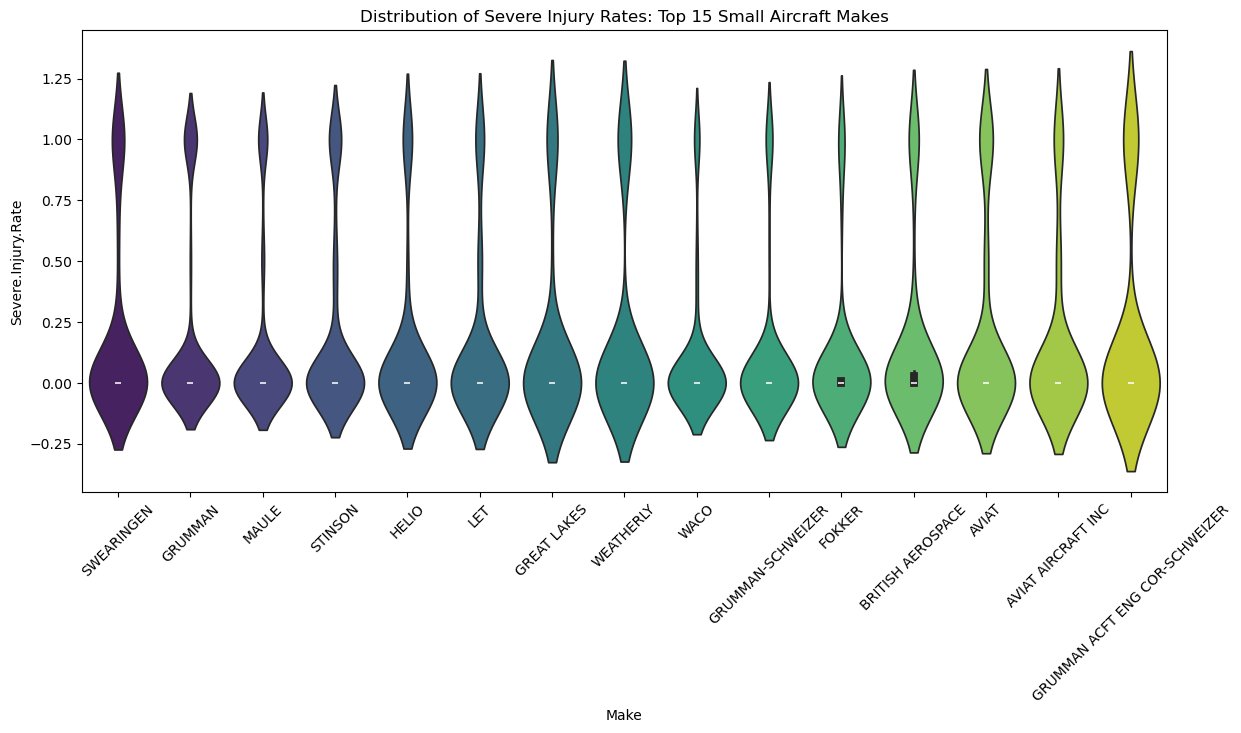

In [5]:
plt.figure(figsize=(14, 6))
# Filter data to only include the top 15 safest small makes for better visibility
small_plot_data = df[df['Make'].isin(top_15_small_injury['Make'])]

sns.violinplot(data=small_plot_data, x='Make', y='Severe.Injury.Rate', palette='viridis')
plt.title('Distribution of Severe Injury Rates: Top 15 Small Aircraft Makes')
plt.xticks(rotation=45)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

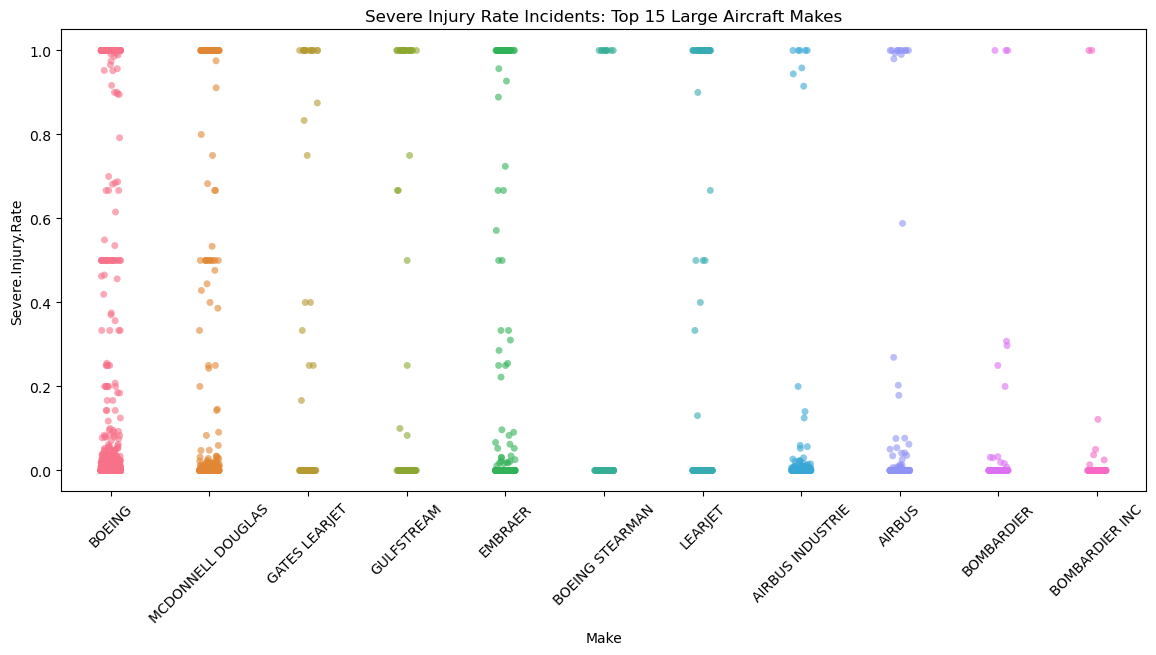

In [6]:
plt.figure(figsize=(14, 6))
large_plot_data = df[df['Make'].isin(top_15_large_injury['Make'])]

sns.stripplot(data=large_plot_data, x='Make', y='Severe.Injury.Rate', hue='Make', jitter=True, alpha=0.6)
plt.title('Severe Injury Rate Incidents: Top 15 Large Aircraft Makes')
plt.xticks(rotation=45)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

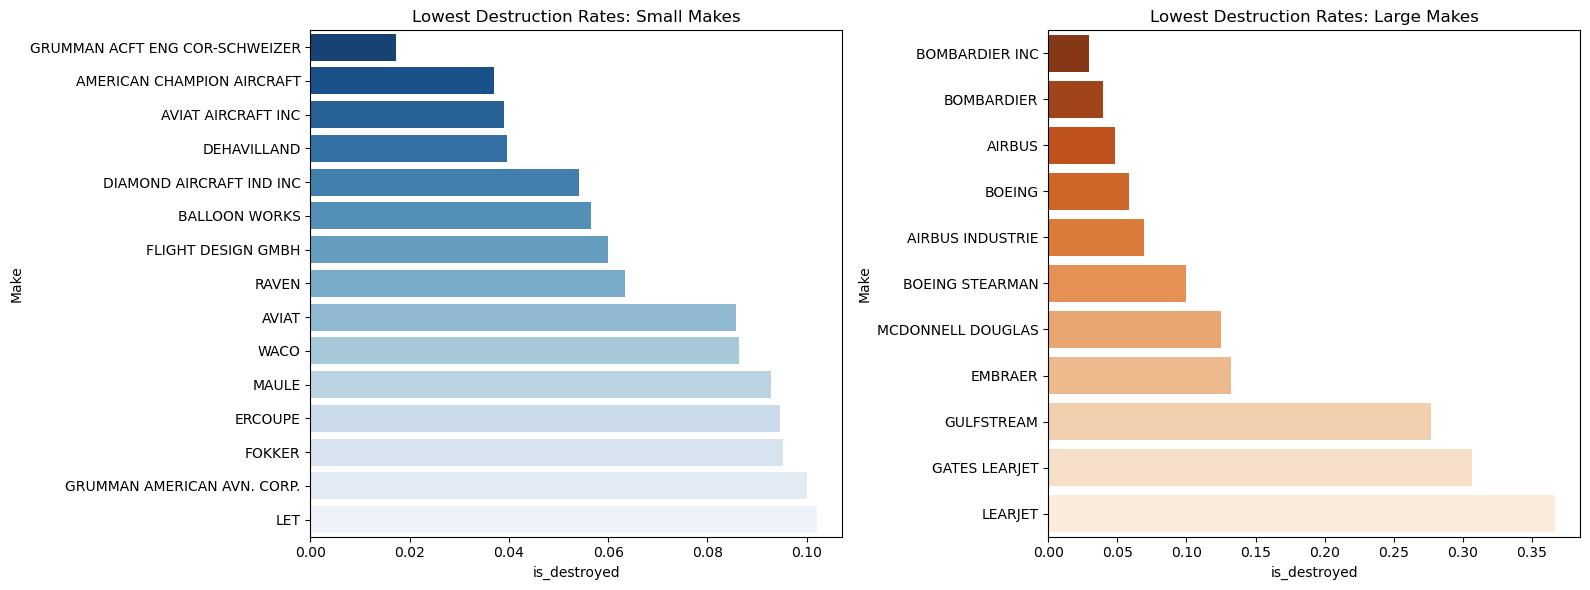

In [7]:
# Calculate destruction rate
destruction_stats = df.groupby(['Size', 'Make'])['is_destroyed'].mean().reset_index()

top_15_small_dest = destruction_stats[destruction_stats['Size'] == 'Small'].nsmallest(15, 'is_destroyed')
top_15_large_dest = destruction_stats[destruction_stats['Size'] == 'Large'].nsmallest(15, 'is_destroyed')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Assigning y (Make) to hue and setting legend=False
sns.barplot(data=top_15_small_dest, x='is_destroyed', y='Make', hue='Make', legend=False, ax=ax[0], palette='Blues_r')
ax[0].set_title('Lowest Destruction Rates: Small Makes')

sns.barplot(data=top_15_large_dest, x='is_destroyed', y='Make', hue='Make', legend=False, ax=ax[1], palette='Oranges_r')
ax[1].set_title('Lowest Destruction Rates: Large Makes')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [8]:
## For high-capacity passenger operations, the data strongly supports a preference for modern, professionally maintained jet fleets with the top recommendations being boeing and airbus

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

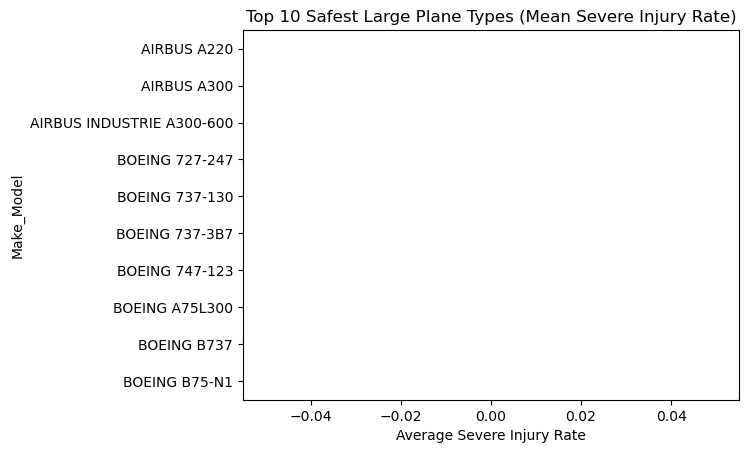

In [9]:
# Analyze by unique Make_Model identifier
large_models = df[df['Size'] == 'Large'].groupby('Make_Model')['Severe.Injury.Rate'].agg(['mean', 'count'])
# Filter for robustness (e.g., at least 5 accidents)
robust_large_models = large_models[large_models['count'] >= 5].nsmallest(10, 'mean')

sns.barplot(
    data=robust_large_models, 
    x='mean', 
    y='Make_Model', 
    hue='Make_Model', 
    palette='magma', 
    legend=False
)

plt.title('Top 10 Safest Large Plane Types (Mean Severe Injury Rate)')
plt.xlabel('Average Severe Injury Rate')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

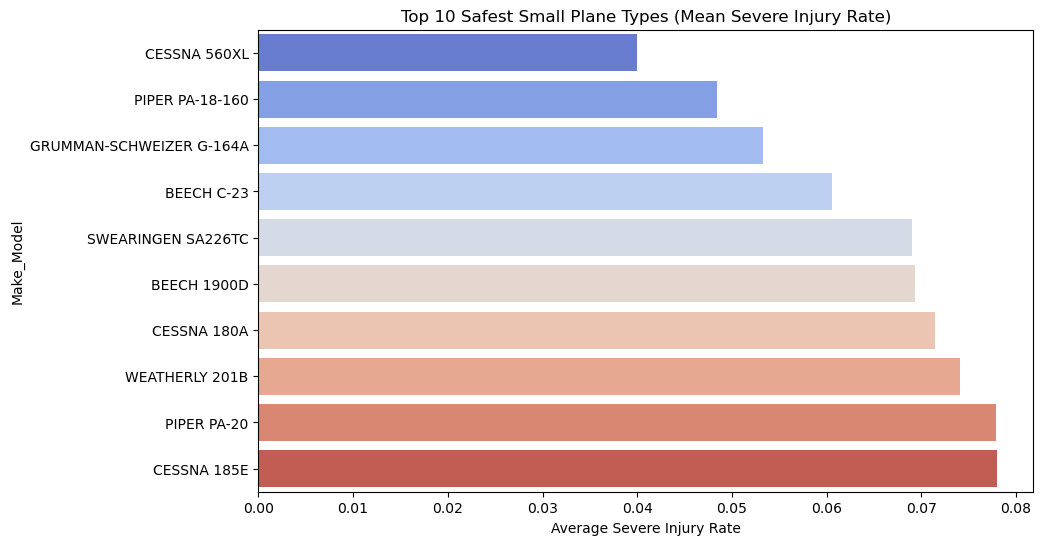

In [10]:
small_models = df[df['Size'] == 'Small'].groupby('Make_Model')['Severe.Injury.Rate'].agg(['mean', 'count'])
robust_small_models = small_models[small_models['count'] >= 20].nsmallest(10, 'mean')

plt.figure(figsize=(10, 6))
# Using index (Make_Model) as hue
sns.barplot(x=robust_small_models['mean'], y=robust_small_models.index, hue=robust_small_models.index, legend=False, palette='coolwarm')
plt.title('Top 10 Safest Small Plane Types (Mean Severe Injury Rate)')
plt.xlabel('Average Severe Injury Rate')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [11]:
#For the larger aircraft category, the injury risk profile is exceptionally low and result in a severe injury rate of zero.
#Small aircraft show a much more varied injury risk profile, the distribution for small aircraft is wider. The likelihood of an accident resulting in a higher fraction of injuries is greater than in the large aircraft category.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

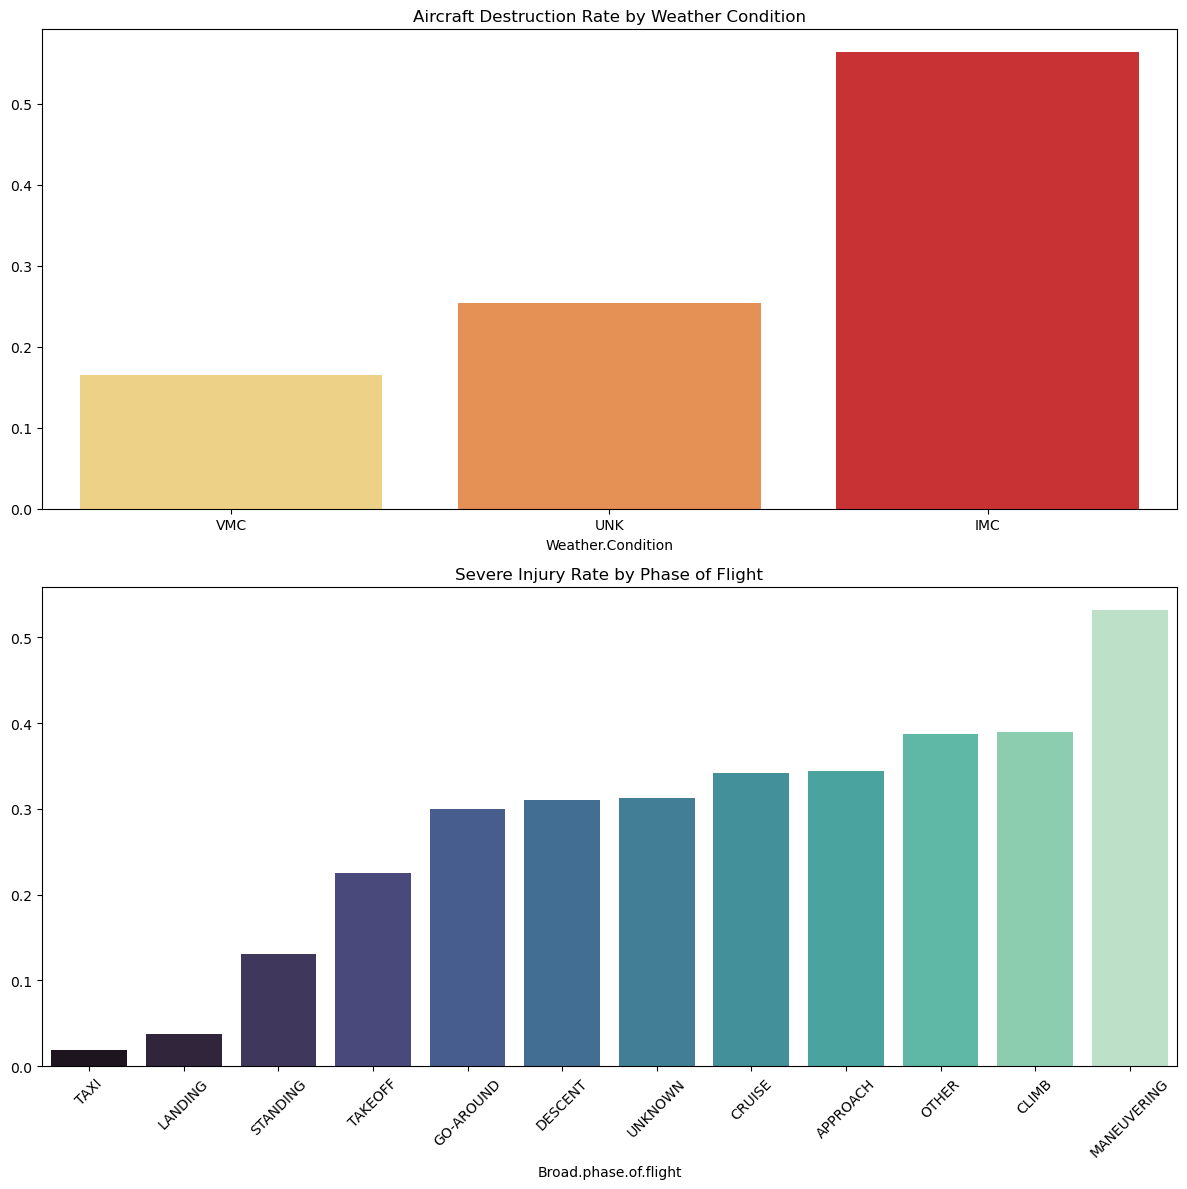

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(12, 12))

# 1. Weather Impact
weather_dest = df.groupby('Weather.Condition')['is_destroyed'].mean().sort_values()
sns.barplot(x=weather_dest.index, y=weather_dest.values, hue=weather_dest.index, legend=False, ax=ax[0], palette='YlOrRd')
ax[0].set_title('Aircraft Destruction Rate by Weather Condition')

# 2. Flight Phase Impact
phase_injury = df.groupby('Broad.phase.of.flight')['Severe.Injury.Rate'].mean().sort_values()
sns.barplot(x=phase_injury.index, y=phase_injury.values, hue=phase_injury.index, legend=False, ax=ax[1], palette='mako')
ax[1].set_title('Severe Injury Rate by Phase of Flight')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Rerun 15/10/2025 to re learn git commands